# 03 Leakage audit

Here we try to catch the final model seeing something it should not. Only train and validation are used, and test labels are never read or printed. Section 2 does rebuild the features for all years, but it compares rows only up to 2021. The final model comes from `reports/final_model.json`, which `02_tuning` writes.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, roc_auc_score

from src import models as M
from src.config import DATASET_PATH, DOCS_DIR, PROCESSED_DIR, TABLES_DIR, TARGET
from src.explain import importance, shap_values
from src.features import CATEGORICAL, DERIVED, build_features, to_number
from src.leakage import FORBIDDEN_RAW, TECHNICAL, check_no_leakage
from src.leakage_audit import (POST_CLIMB, changed_rows, extreme_levels, flip_labels_from, keyword_levels,
                               missing_vs_success, single_feature_auc, with_post_climb_fields)
from src.load import TABLES
from src.split import dev_split, fit_frame, load_features
from src.style import BLUE, GRID, INK, MUTED, ORANGE, apply_style, save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
apply_style()

final = M.load_final_config()
FINAL, TREES, PARAMS, SEEDS = final["features"], final["iterations"], final["params"], tuple(final["seeds"])
tables = {name: pd.read_parquet(PROCESSED_DIR / f"{name}.parquet") for name in TABLES}
train, val = dev_split(load_features())
train_x = with_post_climb_fields(train, tables["exped"], tables["members"])
val_x = with_post_climb_fields(val, tables["exped"], tables["members"])
fit = fit_frame(train_x)
y_val = M.target(val_x)
print(f"fitting rows {len(fit):,}, val rows {len(val_x):,}, features {len(FINAL)}, trees {TREES}, seeds {len(SEEDS)}")

fitting rows 37,448, val rows 5,042, features 34, trees 176, seeds 5


## 1. The guard on forbidden fields

In [2]:
dictionary = pd.read_csv(DOCS_DIR / "data_dictionary.csv", encoding="utf-8-sig", keep_default_na=False)
print(dictionary["timing"].value_counts().to_string())
assert set(dictionary.loc[dictionary["timing"] == "after", "field"]) == FORBIDDEN_RAW
print(f"forbidden fields {len(FORBIDDEN_RAW)}, technical fields {len(TECHNICAL)}")
check_no_leakage(train[FINAL])
print("final features pass the guard")

attempts = POST_CLIMB + ["MSUCCESS", "DEATH", "O2CLIMB", "highpoint_bin", "EXPID", "ANOMALOUS_SEASON"]
stopped = []
for field in attempts:
    try:
        check_no_leakage(pd.DataFrame(columns=FINAL + [field]))
    except ValueError:
        stopped.append(field)
print(f"guard stopped {len(stopped)} of {len(attempts)} attempts:", stopped)
assert stopped == attempts

timing
after        110
before        49
technical     10
forbidden fields 110, technical fields 9
final features pass the guard
guard stopped 10 of 10 attempts: ['HIGHPOINT', 'TERMREASON', 'SMTMEMBERS', 'MPERHIGHPT', 'MSUCCESS', 'DEATH', 'O2CLIMB', 'highpoint_bin', 'EXPID', 'ANOMALOUS_SEASON']


## 2. Future labels and past features
We flip every summit label from a chosen year onwards and rebuild all the features. Everything up to spring of that year has to stay the same. Later rows have to change, otherwise the check would prove nothing.

In [3]:
dataset = pd.read_parquet(DATASET_PATH)
base = build_features(dataset, tables)
rows = []
for cut in (2005, 2018):
    flipped = build_features(dataset, {**tables, "members": flip_labels_from(tables["members"], cut)})
    changed = changed_rows(base, flipped, DERIVED)
    past = (base["YEAR"] < cut) | ((base["YEAR"] == cut) & (base["SEASON"] == 1))
    later = (base["YEAR"] > cut) & (base["YEAR"] <= 2021)
    rows.append({"labels flipped from": cut, "past rows": int(past.sum()), "past rows changed": int(changed[past].sum()),
                 "later rows up to 2021": int(later.sum()), "later rows changed": int(changed[later].sum())})
    assert not changed[past].any() and changed[later].any()
future_check = pd.DataFrame(rows).set_index("labels flipped from")
future_check.to_csv(TABLES_DIR / "03_future_labels.csv")
display(future_check)

,past rows,past rows changed,later rows up to 2021,later rows changed
labels flipped from,,,,
2005,18502,0,23837,23837
2018,38769,0,3334,3334


## 3. What a real leak would look like
We add one forbidden field at a time to the final model. This is only a demonstration, since the guard stops these fields in the real pipeline.

In [4]:
def scores(frame, valid, features):
    model = M.refit_lightgbm(frame, TREES, params=PARAMS, features=features, seeds=SEEDS)
    p = model.predict(valid)
    return roc_auc_score(y_val, p), log_loss(y_val, p)

rows = []
for name, extra in [("final model", [])] + [(f"+ {field}", [field]) for field in POST_CLIMB]:
    auc, loss = scores(fit, val_x, FINAL + extra)
    rows.append({"model": name, "val_roc_auc": auc, "val_log_loss": loss})
canary = pd.DataFrame(rows).set_index("model")
canary.round(4).to_csv(TABLES_DIR / "03_canary.csv")
display(canary.round(4))
assert abs(canary.loc["final model", "val_roc_auc"] - 0.712) < 0.001

,val_roc_auc,val_log_loss
model,,
final model,0.7116,0.6219
+ HIGHPOINT,0.8298,0.4805
+ TERMREASON,0.8472,0.4530
+ SMTMEMBERS,0.9161,0.3638
+ MPERHIGHPT,0.9782,0.1256


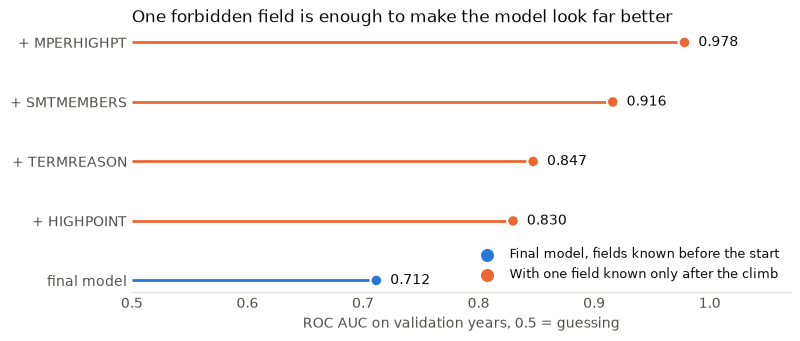

In [5]:
ordered = canary["val_roc_auc"].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 3.4))
y = np.arange(len(ordered))
colors = [BLUE if name == "final model" else ORANGE for name in ordered.index]
ax.hlines(y, 0.5, ordered.to_numpy(), color=colors, lw=2)
ax.scatter(ordered.to_numpy(), y, s=70, color=colors, edgecolors="white", linewidths=1.5, zorder=3)
for yy, value in zip(y, ordered.to_numpy()):
    ax.text(value + 0.012, yy, f"{value:.3f}", va="center", color=INK, fontsize=10)
ax.set_yticks(y, ordered.index, color=INK)
ax.set_xlim(0.5, 1.07)
ax.set_xlabel("ROC AUC on validation years, 0.5 = guessing", color=MUTED)
ax.set_title("One forbidden field is enough to make the model look far better", loc="left", fontsize=12, color=INK)
ax.tick_params(colors=MUTED, length=0)
ax.scatter([], [], s=70, color=BLUE, label="Final model, fields known before the start")
ax.scatter([], [], s=70, color=ORANGE, label="With one field known only after the climb")
ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
save_figure(fig, "03_canary.png")
plt.show()

## 4. Looking for signal where there is none
With shuffled training labels the validation AUC should drop to about 0.5, and a column of random noise should end up near the bottom of the SHAP ranking.

In [6]:
rng = np.random.default_rng(42)
shuffled_auc = []
for _ in range(3):
    shuffled = fit.assign(**{TARGET: rng.permutation(fit[TARGET].to_numpy())})
    shuffled_auc.append(scores(shuffled, val_x, FINAL)[0])
print("val AUC with shuffled training labels:", np.round(shuffled_auc, 3).tolist())
assert all(abs(a - 0.5) < 0.05 for a in shuffled_auc)

noisy_fit = fit.assign(NOISE=rng.normal(size=len(fit)))
noisy_val = val_x.assign(NOISE=rng.normal(size=len(val_x)))
noisy_model = M.refit_lightgbm(noisy_fit, TREES, params=PARAMS, features=FINAL + ["NOISE"], seeds=SEEDS)
noise_rank = importance(shap_values(noisy_model, noisy_val)[0])
print(f"noise column: SHAP rank {noise_rank.index.get_loc('NOISE') + 1} of {len(noise_rank)}, mean |SHAP| {noise_rank['NOISE']:.4f}")
print(f"val AUC with the noise column: {roc_auc_score(y_val, noisy_model.predict(noisy_val)):.3f}")
final_model = M.refit_lightgbm(fit, TREES, params=PARAMS, features=FINAL, seeds=SEEDS)
by_feature = importance(shap_values(final_model, val_x)[0])
print(f"largest feature in the final model: {by_feature.index[0]}, {by_feature.iloc[0] / by_feature.sum():.1%} of all mean |SHAP|")

val AUC with shuffled training labels: [0.468, 0.478, 0.453]


noise column: SHAP rank 31 of 35, mean |SHAP| 0.0007


val AUC with the noise column: 0.712


largest feature in the final model: CROWD_ROUTE, 11.6% of all mean |SHAP|


## 5. Features on their own
How strong each feature is alone on the fitting rows, measured as `max(AUC, 1 - AUC)`. For categories we use out-of-fold success rates, holding out whole expeditions.

This cannot replace section 3: `HIGHPOINT` looks weak by itself and still adds a lot inside the model.

In [7]:
single = single_feature_auc(fit, FINAL, CATEGORICAL)
single.round(4).rename("single_feature_auc").to_csv(TABLES_DIR / "03_single_feature_auc.csv")
display(single.head(10).round(3).to_frame("AUC alone"))
print("single post-climb fields for comparison:")
display(single_feature_auc(fit, POST_CLIMB, []).round(3).to_frame("AUC alone"))

,AUC alone
CROWD_ROUTE_TOTAL,0.632
CROWD_ROUTE,0.630
OTHER_EXPEDITIONS_PEAK,0.625
CROWD_PEAK,0.619
CROWD_PEAK_TOTAL,0.618
ROUTE1,0.612
PEAK_GROUP,0.602
PEAK_SUCCESS_PRIOR,0.600
PEAK_ATTEMPTS_PRIOR,0.592
CITIZEN,0.586


single post-climb fields for comparison:


,AUC alone
MPERHIGHPT,0.850
SMTMEMBERS,0.842
TERMREASON,0.766
HIGHPOINT,0.627


## 6. Missing values
A gap can act as a hidden label if a field is only filled in after a successful climb.

In [8]:
missing = missing_vs_success(fit, FINAL)
display(missing.sort_values("missing_share", ascending=False).round(3))

dev = pd.concat([train_x, val_x], ignore_index=True)
dev["DECADE"] = (to_number(dev["YEAR"]) // 10 * 10).astype(int)
print("share of missing values by decade, train and val:")
display(dev.groupby("DECADE")[["COMRTE", "STDRTE"]].agg(lambda s: s.isna().mean()).round(3))
rows = []
for peak in ("EVER", "AMAD", "CHOY", "MANA", "OTHER"):
    part = dev[(dev["PEAK_GROUP"] == peak) & (dev["DECADE"] < 2010)]
    gap = part["COMRTE"].isna()
    rows.append({"peak": peak, "rows before 2010": len(part), "COMRTE missing": gap.mean(), "success if missing": part.loc[gap, TARGET].astype(float).mean(), "success if known": part.loc[~gap, TARGET].astype(float).mean()})
display(pd.DataFrame(rows).set_index("peak").round(3))
later_rows = load_features()
later_rows = later_rows[later_rows["YEAR"] >= 2018]
print(f"rows from 2018 on, including test years, no labels: {len(later_rows):,}; missing COMRTE {int(later_rows['COMRTE'].isna().sum())}, missing STDRTE {int(later_rows['STDRTE'].isna().sum())}")

,missing_share,success_if_missing,success_if_known
feature,,,
COMRTE,0.145,0.265,0.407
STDRTE,0.123,0.259,0.405
PRIOR_EXPEDITIONS,0.021,0.398,0.386
PRIOR_SUMMITS_PEAK,0.021,0.398,0.386
PRIOR_EXPEDITIONS_PEAK,0.021,0.398,0.386
PRIOR_SUMMITS,0.021,0.398,0.386
AGENCY,0.019,0.343,0.388
CALCAGE,0.015,0.431,0.386
ROUTE1,0.003,0.255,0.387


share of missing values by decade, train and val:


,COMRTE,STDRTE
DECADE,,
1990,0.365,0.315
2000,0.094,0.076
2010,0.0,0.0
2020,0.0,0.0


,rows before 2010,COMRTE missing,success if missing,success if known
peak,,,,
EVER,6303,0.000,NaN,0.368
AMAD,3537,0.000,NaN,0.544
CHOY,5118,0.000,NaN,0.404
MANA,1067,0.044,0.149,0.227
OTHER,2986,0.530,0.304,0.372


rows from 2018 on, including test years, no labels: 14,156; missing COMRTE 0, missing STDRTE 0


## 7. Category values
First the levels with at least 30 rows that almost always end the same way, then the levels whose text mentions an outcome, on train and validation only. Words like `Summit` are normal in agency names and in routes such as `E Ridge-E Summit`, so we read these matches by hand.

In [9]:
TEXT_COLUMNS = ["STATUS", "ROUTE1", "AGENCY", "CITIZEN"]
extreme = extreme_levels(dev, TEXT_COLUMNS)
words = keyword_levels(dev, TEXT_COLUMNS)
extreme.round(3).to_csv(TABLES_DIR / "03_extreme_levels.csv", index=False)
words.round(3).to_csv(TABLES_DIR / "03_outcome_words.csv", index=False)
print(f"levels with success <= 2% or >= 98%: {len(extreme)}, rows {int(extreme['n'].sum()):,} of {len(dev):,}")
display(extreme.head(15).round(3))
print(f"levels whose text mentions an outcome: {len(words)}, rows {int(words['n'].sum()):,} of {len(dev):,}")
display(words.groupby("column")["n"].agg(["size", "sum"]))
display(words[words["column"] != "AGENCY"].round(3))

levels with success <= 2% or >= 98%: 3, rows 140 of 43,011


,column,level,n,success
390,ROUTE1,NE side,69,0.014
573,ROUTE1,SE Face/Ridge,40,0.000
248,ROUTE1,N Col-N Face (Great Couloir),31,0.000


levels whose text mentions an outcome: 57, rows 3,543 of 43,011


,size,sum
column,,
AGENCY,48,3452
ROUTE1,9,91


,column,level,n,success
198,ROUTE1,E Ridge-E Summit from N,32,0.094
281,ROUTE1,N Face (rib to 7500m)-N Ridge,18,0.111
256,ROUTE1,N Face (1984 Spanish rte to 6700m),10,0.600
295,ROUTE1,N Face-E Peak (for traverse of summits),8,0.000
199,ROUTE1,E Ridge-E Summit-N Peak from N,8,0.250
197,ROUTE1,E Ridge-E Summit,8,0.375
522,ROUTE1,S Rib of Central Summit,3,0.000
297,ROUTE1,N Face-E Ridge-E Summit,2,0.000
356,ROUTE1,NE Face-N Plateau-Summit Plateau,2,1.000


## 8. Features not strictly known before the start
`TOTHIRED` and `NOHIRED` count hired staff above base camp, so they are filled in after the climb has begun. If everything these columns add were leakage, the AUC we lose without them would be its upper limit. We also check the rows from expeditions that did not attempt the climb (`TERMREASON` 12; code 11 does not occur in these rows).

In [10]:
expeditions = dev.drop_duplicates(["EXPID", "YEAR"])
high = expeditions[to_number(expeditions["HEIGHTM"]) >= 8000]
low_point, high_point = to_number(high["HIGHPOINT"]).between(1, 7000), to_number(high["HIGHPOINT"]) >= 8000
print(f"8000 m expeditions, TOTHIRED = 0: turned back at or below 7000 m {(high.loc[low_point, 'TOTHIRED'] == 0).mean():.1%} (n={int(low_point.sum())}), "
      f"reached 8000 m or more {(high.loc[high_point, 'TOTHIRED'] == 0).mean():.1%} (n={int(high_point.sum())})")
codes = expeditions.groupby("TERMREASON")["TOTHIRED"].agg(n="size", zero_share=lambda s: (s == 0).mean())
display(codes.round(3))

without = [f for f in FINAL if f not in ("TOTHIRED", "NOHIRED", "HIRED_PER_MEMBER")]
auc, loss = scores(fit, val_x, without)
base_auc, base_loss = canary.loc["final model", ["val_roc_auc", "val_log_loss"]]
print(f"without TOTHIRED, NOHIRED, HIRED_PER_MEMBER: val AUC {auc:.3f} (final {base_auc:.3f}), log loss {loss:.3f} (final {base_loss:.3f})")

never = to_number(dev["TERMREASON"]).isin([11, 12])
print(f"rows with TERMREASON 11-12: {int(never.sum())} of {len(dev):,} ({never.mean():.2%}), success {dev.loc[never, TARGET].astype(float).mean():.3f}, TOTHIRED = 0 in {(dev.loc[never, 'TOTHIRED'] == 0).mean():.1%}")
in_val = to_number(val_x["TERMREASON"]).isin([11, 12]).to_numpy()
p_final = final_model.predict(val_x)
print(f"val rows with these codes: {int(in_val.sum())}; val AUC without them {roc_auc_score(y_val[~in_val], p_final[~in_val]):.4f}, with them {roc_auc_score(y_val, p_final):.4f}")

8000 m expeditions, TOTHIRED = 0: turned back at or below 7000 m 40.0% (n=513), reached 8000 m or more 23.3% (n=3634)


,n,zero_share
TERMREASON,,
0,113,0.593
1,4973,0.276
2,103,0.262
3,4,0.25
4,1031,0.399
5,913,0.395
6,164,0.421
7,421,0.463
8,181,0.293


without TOTHIRED, NOHIRED, HIRED_PER_MEMBER: val AUC 0.702 (final 0.712), log loss 0.631 (final 0.622)
rows with TERMREASON 11-12: 52 of 43,011 (0.12%), success 0.000, TOTHIRED = 0 in 46.2%


val rows with these codes: 22; val AUC without them 0.7095, with them 0.7116
